<a href="https://colab.research.google.com/github/ck3378/Small-Language-Model/blob/main/Small_language_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1) The below model is a Small Language model sepecific to Diease and its   symptoms


2) The model is trained on QuyenAnhDE/Diseases_Symptoms dataset along with pre-trained distilgpt2 for tokenization

3) The model is ready to response for 400 diseases at the moment , also generate the responses for unkonwn dieases

4) Although the model does generate responses for diseases not present in the dataset , but lacks acuracy for the responses generated

5) The future scope of this lies in using a larger dataset. The present dataset has 382 unique records , while a dataset with 2000 records will train the model better , for accurate results

6) Use cases : Sites that specifically talk about disease and its   symptoms . Apollo and Practo can be a leading example here . The model can be downloaded and integrated after improved accuracy .

7) [Dataset for model](https://huggingface.co/datasets/QuyenAnhDE/Diseases_Symptoms/viewer/default/train?p=1&views%5B%5D=train)


In [ ]:
!pip install torch torchtext transformers sentencepiece pandas tqdm datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.6 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset, DatasetDict , Dataset
import pandas as pd
import tensorflow as tf
import datasets
from tqdm import tqdm
import time


In [ ]:
data_sample = load_dataset("QuyenAnhDE/Diseases_Symptoms")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/381 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


Diseases_Symptoms.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/400 [00:00<?, ? examples/s]

In [ ]:
data_sample

DatasetDict({
    train: Dataset({
        features: ['Code', 'Name', 'Symptoms', 'Treatments'],
        num_rows: 400
    })
})

In [ ]:
#convert data to pandas data set
updated_data= [{'Name':item['Name'], 'Symptoms' :item['Symptoms']} for item in data_sample['train']]

In [ ]:
df = pd.DataFrame(updated_data)

In [ ]:
df.head(5)

,Name,Symptoms
0,Panic disorder,"Palpitations, Sweating, Trembling, Shortness o..."
1,Vocal cord polyp,"Hoarseness, Vocal Changes, Vocal Fatigue"
2,Turner syndrome,"Short stature, Gonadal dysgenesis, Webbed neck..."
3,Cryptorchidism,"Absence or undescended testicle(s), empty scro..."
4,Ethylene glycol poisoning-1,"Nausea, vomiting, abdominal pain, General mala..."


In [ ]:
#extract the symptoms
df['Symptoms'] = df['Symptoms'].apply(lambda x: ','.join (x.split(',')))

In [ ]:
from transformers import GPT2Tokenizer, GPT2LMHeadModel
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader , random_split
import numpy as np

In [ ]:
#find the compute device
if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  #try:
   #device = torch.device("mps") #using mps for mac  issues faced: - Pytorch is not supported for mps in collab
  #except Exception:
    device = torch.device("cpu")

In [ ]:
device #will show device type , shows mps for mac but since Pytorch is not supported switched to cpu

device(type='cpu')

In [ ]:
tokenizer = GPT2Tokenizer.from_pretrained('distilgpt2') #tokenizer here splits texts into smaller sentences
model = GPT2LMHeadModel.from_pretrained('distilgpt2').to(device) # we use pretarined model of distilgpt2 for generating tokens

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [ ]:
model

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-5): 6 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [ ]:
BATCH_SIZE = 8

In [ ]:
df.describe()

,Name,Symptoms
count,400,400
unique,392,395
top,Sciatica,"Swelling, pain, dry mouth, bad taste"
freq,3,3


In [ ]:
#Prepare Dataset
class LanguageDataset(Dataset):
  def __init__(self, df, tokenizer):
    self.labels = df.columns
    self.data = df.to_dict(orient='records')
    self.tokenizer = tokenizer
    x = self.fittest_max_length(df)
    self.max_length = x

  def __len__(self):
    return len(self.data)

  def __getitem__(self, idx):
      x = self.data[idx][self.labels[0]] #value of first lable of that row
      y = self.data[idx][self.labels[1]] #value of second lable of that row
      text = f"{x} | {y}" #formatting values into a single string
      tokens = self.tokenizer.encode_plus(text , return_tensors='pt', max_length=128 , padding = 'max_length', truncation=True) #converts raw texts into tokens
      return tokens


  def fittest_max_length(self, df):
    max_length = max(len(max(df[self.labels[0]],key = len)), len (max(df[self.labels[1]],key = len)))
    x=2
    while x < max_length:
      x*=2
    return x

In [ ]:
#casting the dataframe
data_sample = LanguageDataset(df, tokenizer)

In [ ]:
data_sample

In [ ]:
train_size = int(0.8 * len(data_sample))
val_size = len(data_sample) - train_size
train_data, val_data= random_split(data_sample, [train_size, val_size])

In [ ]:
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE)

In [ ]:
num_epochs = 8

In [ ]:
batch_size = BATCH_SIZE
model_name = 'distilgpt2'
gpu = 0

In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.pad_token_type_id)
optimizer = optim.Adam(model.parameters(), lr=5e-4) # learning rate of the model
tokenizer.pad_token = tokenizer.eos_token

In [ ]:
results = pd.DataFrame(columns=['epoch', 'transformer' , 'batch_size' , 'gpu' , 'training_loss' , 'validation_loss' , 'epoch_duration_sec'])

Training Epoch 1/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:53<00:00, 11.83s/it, Training Loss=0.0813]
Training Epoch 2/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:28<00:00, 11.22s/it, Training Loss=0.0643]
Training Epoch 3/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:35<00:00, 11.40s/it, Training Loss=0.0866]
Training Epoch 4/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:25<00:00, 11.13s/it, Training Loss=0.0734]
Training Epoch 5/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:24<00:00, 11.12s/it, Training Loss=0.0708]
Training Epoch 6/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:25<00:00, 11.14s/it, Training Loss=0.0629]
Training Epoch 7/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:30<00:00, 11.25s/it, Training Loss=0.0742]
Training Epoch 8/8 Batch Size: 8 , Transformer: distilgpt2: 100%|██████████| 40/40 [07:30<

Epoch:8 , Validation loss : 1.0078375339508057


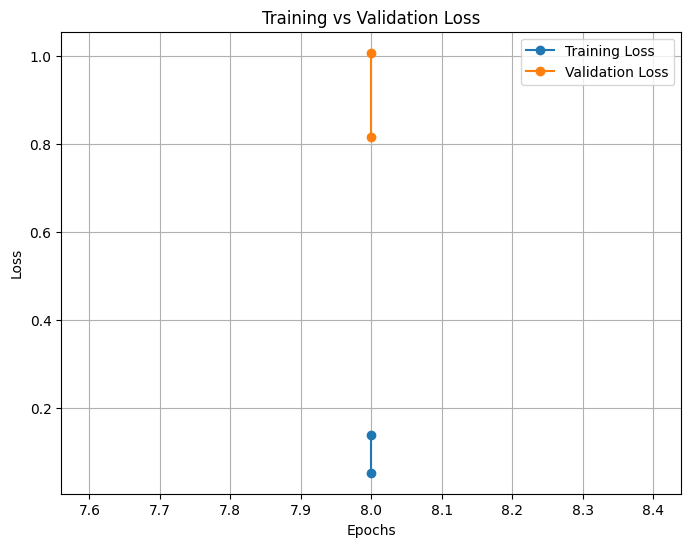

In [ ]:

#tarining loop
for epoch in range(num_epochs):
  start_time = time.time()
  model.train()
  epoch_training_loss = 0
  train_iterator = tqdm(train_loader, desc=f"Training Epoch {epoch+1}/{num_epochs} Batch Size: {batch_size} , Transformer: {model_name}")
  for batch in train_iterator:
    optimizer.zero_grad()
    inputs = batch['input_ids'].squeeze(1).to(device)
    targets = inputs.clone()
    outputs = model(input_ids = inputs,  labels=targets)
    loss = outputs.loss
    loss.backward()
    optimizer.step()
    train_iterator.set_postfix({'Training Loss' : loss.item()})
    epoch_training_loss += loss.item()
  avg_epoch_training_loss = epoch_training_loss / len(train_iterator)

#validation
model.eval()
epoch_validation_loss = 0
total_loss = 0
valid_iterator = tqdm(val_loader, desc=f"Validation Epoch {epoch+1}/{num_epochs} ")
with torch.no_grad():
  for batch in valid_iterator:
    inputs = batch['input_ids'].squeeze(1).to(device)
    targets = inputs.clone()
    outputs = model(input_ids = inputs,  labels=targets)
    loss = outputs.loss
    total_loss +=loss
    valid_iterator.set_postfix({'Validation Loss' : loss.item()})
    epoch_validation_loss += loss.item()

avg_epoch_validation_loss = epoch_validation_loss / len(val_loader)

end_time = time.time()
epoch_duration_sec= end_time - start_time

new_row = {'transformer': model_name, 'batch_size': batch_size, 'gpu': gpu,'epoch': epoch+1 , 'training_loss': avg_epoch_training_loss, 'validation_loss': avg_epoch_validation_loss, 'epoch_duration_sec': epoch_duration_sec}
results.loc[len(results)] = new_row
print(f"Epoch:{epoch + 1} , Validation loss : {total_loss / len(val_loader)}")


import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.plot(results['epoch'], results['training_loss'], label="Training Loss", marker='o')
plt.plot(results['epoch'], results['validation_loss'], label="Validation Loss", marker='o')

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

**X-axis** (Epochs): Training progress. Here it’s only showing values around epoch 8.

**Y-axis** (Loss): Error value — lower is better.

**Blue dot**: Training loss at epoch 8.

**Orange dot**: Validation loss at epoch 8.


**Observations**

Training Loss : Very low → your model is fitting the training data well.

Validation Loss : Much higher → model is not generalizing well to unseen data.

Gap between training and validation: Big gap = overfitting signal.

In [ ]:
input_str = "Depression"

In [ ]:
input_ids = tokenizer.encode(input_str, return_tensors='pt').to(device)

In [ ]:
input_ids

tensor([[12156,  2234]])

In [ ]:
output = model.generate(
    input_ids,
    max_length=20,
    num_return_sequences=1,
    do_sample=True,
    top_k=8,
    top_p=0.95,
    temperature=0.5,
    repetition_penalty=1.2
)

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


In [ ]:
output

tensor([[12156,  2234,   286, 48276,   930,  2129,  2412,   319,   262,  2176,
          7460,    11,  9751,    11, 38912, 50256]])

In [ ]:
decoded_output = tokenizer.decode(output[0], skip_special_tokens=True)

In [ ]:
decoded_output

'Depression of Anxiety | Depends on the specific symptoms, anxiety, sweating'